# Historical Meteorological Analysis — Data Cleaning & EDA

**Adapted from the original notebook written by the project author.** This version preserves the original analysis sequence, calculations, charts, and cell outputs. Explanatory notes have been added to make the analysis easier to follow. Some original calculations and labels still require a separate scientific review.

In [1]:
%matplotlib inline
# Read the station's text file into a table (DataFrame). The first lines are metadata rather than daily observations.
# CLIMATOLOGICAL DATASET

#ESTACION  : 26131
#NOMBRE    : NAVOJOA (FFCC)
#ESTADO    : SONORA
#MUNICIPIO : NAVOJOA
#LATITUD   : 027.081°
#LONGITUD  : -109.445°
#ALTITUD   : 41 msnm
#EMISION   : 06/04/2020

# Import NumPy and pandas for manipulating and analyzing data.
import numpy as np
import pandas as pd
# Import Seaborn and Matplotlib for data visualization.
import seaborn as sns
import matplotlib.pyplot as plt


# Create a DataFrame (table of data).
# Read the original Navojoa climatology text file.
# Skip the first 19 lines, which contain station metadata.
# The expression \\s refers to whitespace, and + means one or more.
# Thus, \\s+ separates columns using one or more whitespace characters.
# Assign readable names to each column.
df0 = pd.read_csv('ClimatologiaNavojoa.txt', skiprows=19, sep='\s+', names=["Fecha", "Precip (mm)", "Evap (mm)","Tmax (°C)","Tmin (°C)"]) 
df0.head() #leer las primeros 5 datos


,Fecha,Precip (mm),Evap (mm),Tmax (°C),Tmin (°C)
0,01/01/1931,0,Nulo,28,8
1,02/01/1931,0,Nulo,29,7
2,03/01/1931,0,Nulo,29,9
3,04/01/1931,0,Nulo,29,6
4,05/01/1931,0,Nulo,26,5


## Reading and preparing the data

We load the daily station data. The source uses `Nulo` for missing values, which is different from a measured zero.

In [2]:
# Convert the source label for missing observations into a missing-data value that Python can recognize.
# Replace the original 'Nulo' markers with missing values (NaN).
# With inplace=True, the changes are saved directly in df0.
df0.replace("Nulo", np.nan, inplace=True)

,Fecha,Precip (mm),Evap (mm),Tmax (°C),Tmin (°C)
0,01/01/1931,0,NaN,28,8
1,02/01/1931,0,NaN,29,7
2,03/01/1931,0,NaN,29,9
3,04/01/1931,0,NaN,29,6
4,05/01/1931,0,NaN,26,5
...,...,...,...,...,...
13400,28/07/1993,0,NaN,39,22
13401,29/07/1993,4.5,NaN,40,23
13402,30/07/1993,0,NaN,36,24
13403,31/07/1993,0,NaN,39,23


In [3]:
# Inspect the DataFrame structure as part of exploratory data analysis.
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 13405 entries, 0 to 13404
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Fecha        13405 non-null  str  
 1   Precip (mm)  13370 non-null  str  
 2   Evap (mm)    0 non-null      str  
 3   Tmax (°C)    13322 non-null  str  
 4   Tmin (°C)    13293 non-null  str  
dtypes: str(5)
memory usage: 523.8 KB


In [4]:
# Remove a column or row from the working table. We should verify the reason for each removal before changing it.
# The previous output shows the evaporation column
# has no usable measurements, so we remove it.
# axis=1 indicates that a column is being removed.
# inplace=True keeps this modification in the existing DataFrame.
df0.drop("Evap (mm)", axis=1, inplace=True)
df0

/tmp/ipykernel_2520/2960327777.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df0.drop("Evap (mm)", axis=1, inplace=True)


,Fecha,Precip (mm),Tmax (°C),Tmin (°C)
0,01/01/1931,0,28,8
1,02/01/1931,0,29,7
2,03/01/1931,0,29,9
3,04/01/1931,0,29,6
4,05/01/1931,0,26,5
...,...,...,...,...
13400,28/07/1993,0,39,22
13401,29/07/1993,4.5,40,23
13402,30/07/1993,0,36,24
13403,31/07/1993,0,39,23


In [5]:
# Remove a column or row from the working table. We should verify the reason for each removal before changing it.
# Drop row 13404, an invalid trailing record in the original import.
# axis=0 means a row is being removed.
# inplace=True applies the removal directly to the table.
df0.drop(13404, axis=0, inplace=True)
df0

/tmp/ipykernel_2520/352289835.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df0.drop(13404, axis=0, inplace=True)


,Fecha,Precip (mm),Tmax (°C),Tmin (°C)
0,01/01/1931,0,28,8
1,02/01/1931,0,29,7
2,03/01/1931,0,29,9
3,04/01/1931,0,29,6
4,05/01/1931,0,26,5
...,...,...,...,...
13399,27/07/1993,0,39,24
13400,28/07/1993,0,39,22
13401,29/07/1993,4.5,40,23
13402,30/07/1993,0,36,24


In [6]:
# Convert text values into numbers so Python can calculate statistics and make plots.
# Convert precipitation and maximum/minimum temperature columns to numeric values.
df0["Precip (mm)"]= pd.to_numeric(df0["Precip (mm)"])
df0["Tmax (°C)"]= pd.to_numeric(df0["Tmax (°C)"])
df0["Tmin (°C)"]= pd.to_numeric(df0["Tmin (°C)"]) 
# Check the result.
df0.dtypes

Fecha              str
Precip (mm)    float64
Tmax (°C)      float64
Tmin (°C)      float64
dtype: object

In [7]:
# Show descriptive statistics such as count, mean, standard deviation and quartiles.
# Display summary statistics for the dataset.
df0.describe()

,Precip (mm),Tmax (°C),Tmin (°C)
count,13370.000000,13322.000000,13293.000000
mean,1.015999,34.195016,14.528549
std,6.192861,6.081358,7.343251
min,0.000000,11.000000,-7.000000
25%,0.000000,30.000000,9.000000
50%,0.000000,35.000000,13.000000
75%,0.000000,39.000000,21.000000
max,254.000000,52.000000,40.000000


## Exploratory statistics

Here we inspect descriptive statistics before aggregating the data. Counts, means, and distributions help us understand what is recorded and what is missing.

In [8]:
# Create a copy before processing dates.
df=df0.copy()
df

,Fecha,Precip (mm),Tmax (°C),Tmin (°C)
0,01/01/1931,0.0,28.0,8.0
1,02/01/1931,0.0,29.0,7.0
2,03/01/1931,0.0,29.0,9.0
3,04/01/1931,0.0,29.0,6.0
4,05/01/1931,0.0,26.0,5.0
...,...,...,...,...
13399,27/07/1993,0.0,39.0,24.0
13400,28/07/1993,0.0,39.0,22.0
13401,29/07/1993,4.5,40.0,23.0
13402,30/07/1993,0.0,36.0,24.0


In [9]:
# Tell pandas to interpret the date column as calendar dates (day/month/year).
# Parse the 'Fecha' values as calendar dates.
df["Fecha"]= pd.to_datetime(df["Fecha"], dayfirst=True)
# Verify that the column type was changed correctly.
df.dtypes

Fecha          datetime64[us]
Precip (mm)           float64
Tmax (°C)             float64
Tmin (°C)             float64
dtype: object

In [10]:
# Extract year and month into separate columns.
df["Mes"]= df['Fecha'].dt.month
df["Año"]= df['Fecha'].dt.year
# Inspect the updated DataFrame.
df

,Fecha,Precip (mm),Tmax (°C),Tmin (°C),Mes,Año
0,1931-01-01,0.0,28.0,8.0,1,1931
1,1931-01-02,0.0,29.0,7.0,1,1931
2,1931-01-03,0.0,29.0,9.0,1,1931
3,1931-01-04,0.0,29.0,6.0,1,1931
4,1931-01-05,0.0,26.0,5.0,1,1931
...,...,...,...,...,...,...
13399,1993-07-27,0.0,39.0,24.0,7,1993
13400,1993-07-28,0.0,39.0,22.0,7,1993
13401,1993-07-29,4.5,40.0,23.0,7,1993
13402,1993-07-30,0.0,36.0,24.0,7,1993


In [11]:
# Group records sharing the same month or year before calculating their summary statistics.
#-----------------------------------------------------------------------------------------------------------------------------
# Next, calculate monthly averages for the variables.
#-----------------------------------------------------------------------------------------------------------------------------



# Create an array of unique month numbers.
mes_unico = pd.unique(df["Mes"])
# Group all daily observations by their month.
mes= df.groupby("Mes")
# Create empty lists to store the monthly mean values.
precip_mensual= []
Tmax_mensual= []
Tmin_mensual= []

for i in range(len(mes_unico)):
    
    # Select the observations belonging to the current month.
    mes_i= mes.get_group(int(mes_unico[i]))
    # Append the mean of recorded daily precipitation for this month.
    precip_mensual.append(np.mean(mes_i["Precip (mm)"]))
    # Append the monthly mean of recorded daily maximum temperatures.
    Tmax_mensual.append(np.mean(mes_i["Tmax (°C)"]))
    # Append the monthly mean of recorded daily minimum temperatures.
    Tmin_mensual.append(np.mean(mes_i["Tmin (°C)"]))
    



## Monthly summaries

These cells group observations by the month of the year. The original code calculates averages of daily values: **average daily precipitation is not total monthly rainfall**.

In [12]:
# Create a summary DataFrame containing the monthly values.

datos_m = {
    
    'Mes' : mes_unico,
    'Precipitacion mensual': precip_mensual,
    'Tmax mensual': Tmax_mensual,
    'Tmin mensual': Tmin_mensual
}

dfm = pd.DataFrame(datos_m)
dfm

,Mes,Precipitacion mensual,Tmax mensual,Tmin mensual
0,1,0.606265,27.084158,6.979373
1,2,0.443551,28.838938,7.473451
2,3,0.215277,31.239274,8.545301
3,4,0.011008,34.236441,10.594915
4,5,0.000925,36.686486,13.870270
5,6,0.383523,38.966696,20.997371
6,7,2.692464,38.682485,23.886109
7,8,3.696030,38.185325,23.190969
8,9,2.340299,38.190476,22.279048
9,10,0.809315,36.548624,17.554128


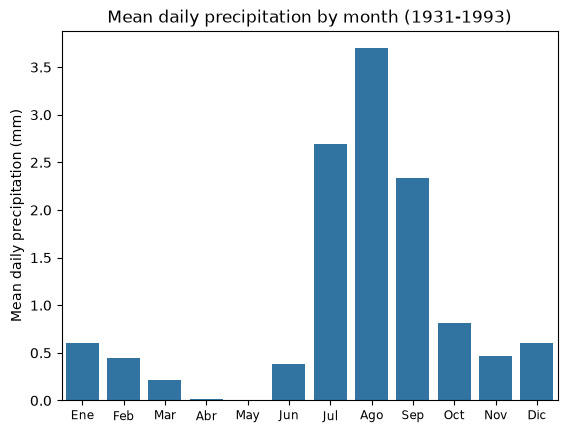

In [13]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing mean daily precipitation by calendar month.
sns.barplot(x=mes_unico,y=precip_mensual)
# Month labels for the horizontal axis.
Meses = ('Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul','Ago','Sep','Oct','Nov','Dic')
# Set horizontal-axis tick positions.
N_mes = np.arange(len(mes_unico))
plt.xticks(N_mes, Meses, size = 'small')
# Label the vertical axis.
plt.ylabel('Mean daily precipitation (mm)')
# Add the chart title.
plt.title('Mean daily precipitation by month (1931-1993)')
# Display the figure.
plt.show()

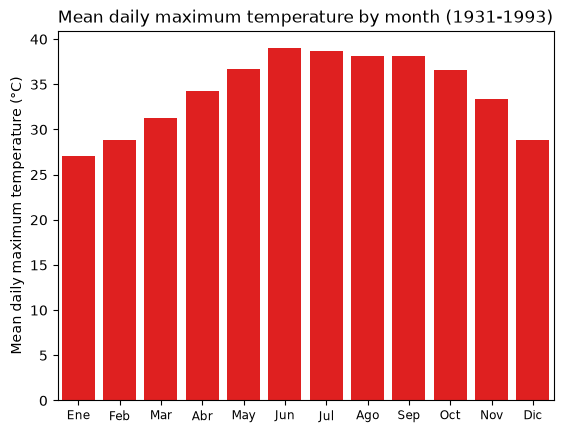

In [14]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing mean daily maximum temperature by month.
sns.barplot(x=mes_unico,y=Tmax_mensual,color='r')
# Month labels for the horizontal axis.
Meses = ('Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul','Ago','Sep','Oct','Nov','Dic')
# Set horizontal-axis tick positions.
N_mes = np.arange(len(mes_unico))
plt.xticks(N_mes, Meses, size = 'small')
# Label the vertical axis.
plt.ylabel('Mean daily maximum temperature (°C)')
# Add the chart title.
plt.title('Mean daily maximum temperature by month (1931-1993)')
# Display the figure.
plt.show()

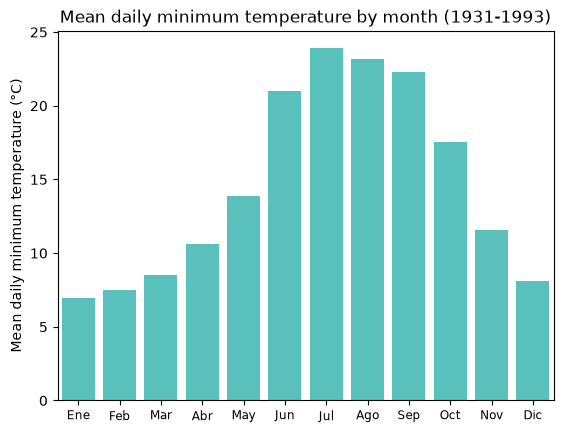

In [15]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing mean daily minimum temperature by month.
sns.barplot(x=mes_unico,y=Tmin_mensual,color='#48D1CC')
# Month labels for the horizontal axis.
Meses = ('Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul','Ago','Sep','Oct','Nov','Dic')
# Set horizontal-axis tick positions.
N_mes = np.arange(len(mes_unico))
plt.xticks(N_mes, Meses, size = 'small')
# Label the vertical axis.
plt.ylabel('Mean daily minimum temperature (°C)')
# Add the chart title.
plt.title('Mean daily minimum temperature by month (1931-1993)')
# Display the figure.
plt.show()

In [16]:
# Group records sharing the same month or year before calculating their summary statistics.
#-----------------------------------------------------------------------------------------------------------------------------
# Next, calculate annual averages for the variables.
#-----------------------------------------------------------------------------------------------------------------------------


# Create an array containing the years in the records.
año_unico = pd.unique(df["Año"])
# Group observations by year.
año= df.groupby("Año")
# Initialize lists to store annual mean values.
precip_anual= []
Tmax_anual= []
Tmin_anual= []

for i in range(len(año_unico)):
    
    # Select observations for the current year.
    año_i = año.get_group(int(año_unico[i]))
    # Append the mean daily precipitation for this year.
    precip_anual.append(np.mean(año_i["Precip (mm)"]))
    # Append the monthly mean of recorded daily maximum temperatures.
    Tmax_anual.append(np.mean(año_i["Tmax (°C)"]))
    # Append the monthly mean of recorded daily minimum temperatures.
    Tmin_anual.append(np.mean(año_i["Tmin (°C)"]))



In [17]:
# Create a DataFrame summarizing values by year.

datos_a = {
    
    'Año' : año_unico,
    'Precipitacion anual': precip_anual,
    'Tmax anual': Tmax_anual,
    'Tmin anual': Tmin_anual
}

dfa = pd.DataFrame(datos_a)
dfa.head()

,Año,Precipitacion anual,Tmax anual,Tmin anual
0,1931,1.221918,37.334247,15.350685
1,1932,0.494536,36.581169,11.711039
2,1933,0.397143,37.588571,14.911429
3,1934,0.879452,38.767123,15.879452
4,1935,1.284932,37.509589,15.673973


## Annual summaries

Annual averages and comparisons require care because the number of available observations differs across years.

/tmp/ipykernel_2520/423382579.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);


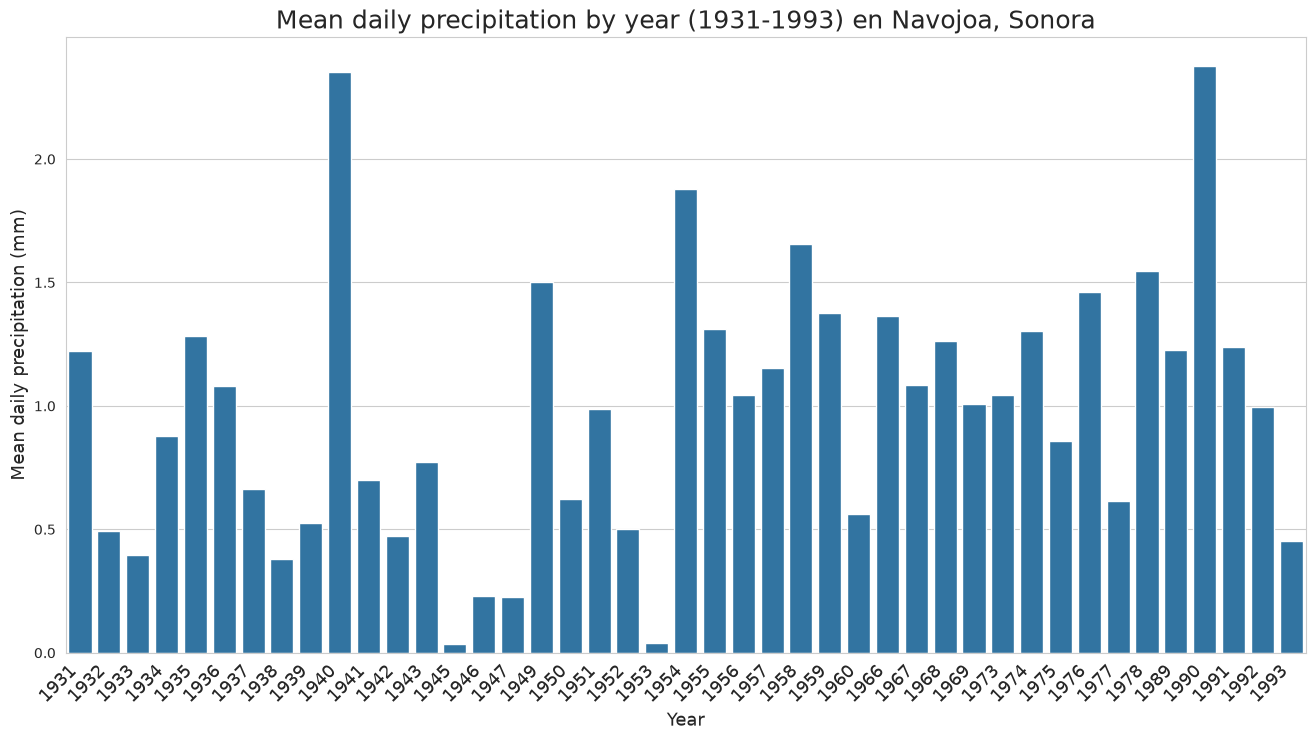

In [18]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing annual mean daily precipitation (not total rainfall).
# Configure the plotting style.
sns.set_style('whitegrid')
# Make this figure larger to improve readability
# because it includes many years of observations.
plt.figure(figsize=(16,8))
# Set horizontal-axis tick positions.
g=sns.barplot(x=año_unico, y=precip_anual);
# Rotate year labels by 45 degrees to make them readable.
g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);

plt.xlabel('Year', fontsize=13)
# Label the vertical axis.
plt.ylabel('Mean daily precipitation (mm)', fontsize=13)
# Add the chart title.
plt.title('Mean daily precipitation by year (1931-1993) en Navojoa, Sonora', fontsize=18)
# Display the figure.
plt.show()

/tmp/ipykernel_2520/171273346.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);


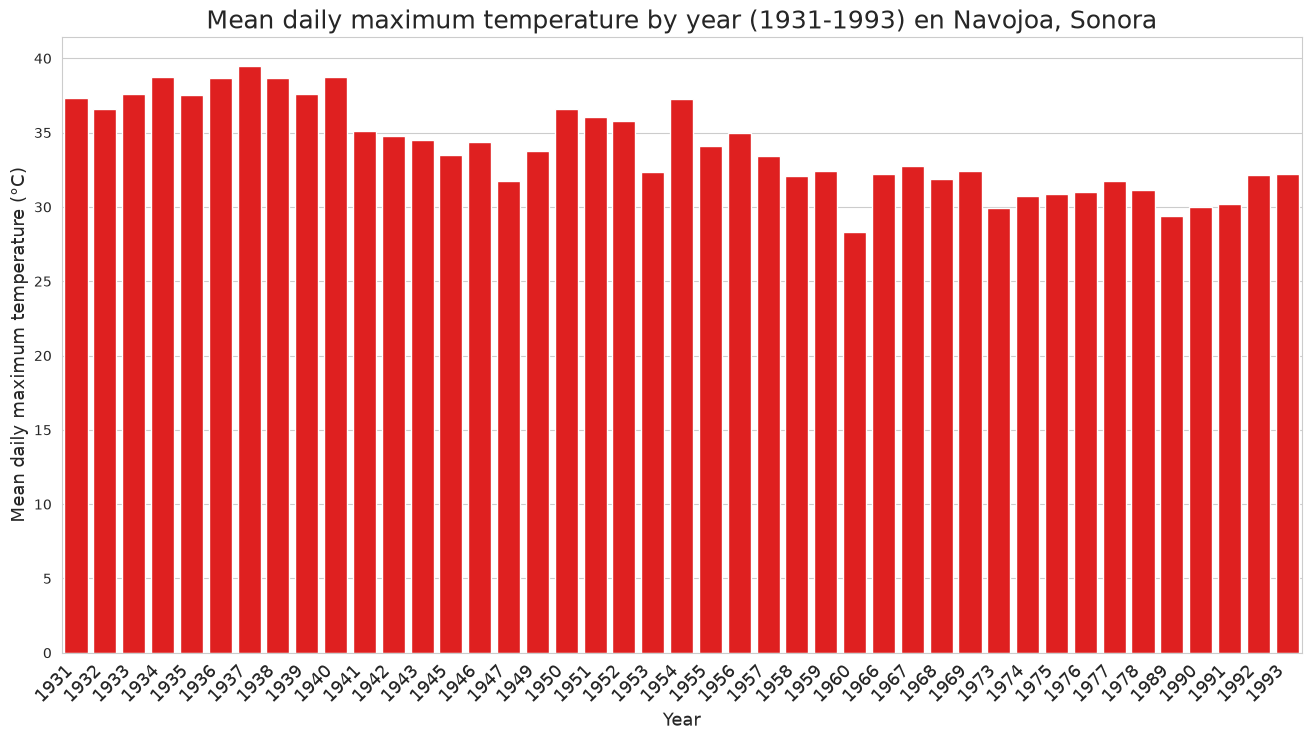

In [19]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing mean daily maximum temperature by year.
# Configure the plotting style.
sns.set_style('whitegrid')
# Make this figure larger to improve readability
# because it includes many years of observations.
plt.figure(figsize=(16,8))
# Set horizontal-axis tick positions.
g=sns.barplot(x=año_unico, y=Tmax_anual,color='r');
# Rotate year labels by 45 degrees to make them readable.
g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);

plt.xlabel('Year', fontsize=13)
# Label the vertical axis.
plt.ylabel('Mean daily maximum temperature (°C)', fontsize=13)
# Add the chart title.
plt.title('Mean daily maximum temperature by year (1931-1993) en Navojoa, Sonora', fontsize=18)
# Display the figure.
plt.show()

/tmp/ipykernel_2520/445721388.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);


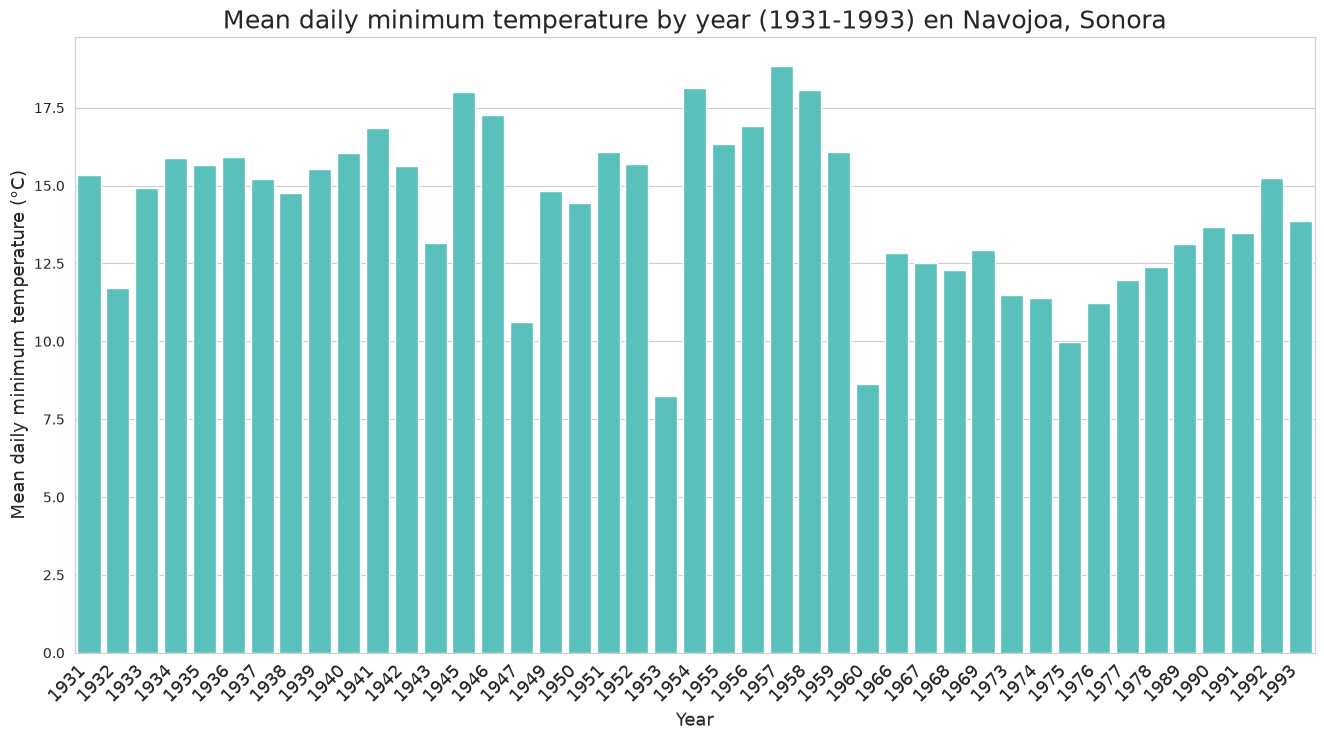

In [20]:
# Draw a bar chart to compare summary values across months or years. Check whether the calculation is a mean or total.
# Bar chart showing mean daily minimum temperature by year.
# Configure the plotting style.
sns.set_style('whitegrid')
# Make this figure larger to improve readability
# because it includes many years of observations.
plt.figure(figsize=(16,8))
# Set horizontal-axis tick positions.
g=sns.barplot(x=año_unico, y=Tmin_anual, color='#48D1CC');
# Rotate year labels by 45 degrees to make them readable.
g.set_xticklabels(g.get_xticklabels(), rotation=45, horizontalalignment='right', fontsize=13);

plt.xlabel('Year', fontsize=13)
# Label the vertical axis.
plt.ylabel('Mean daily minimum temperature (°C)', fontsize=13)
# Add the chart title.
plt.title('Mean daily minimum temperature by year (1931-1993) en Navojoa, Sonora', fontsize=18)
# Display the figure.
plt.show()

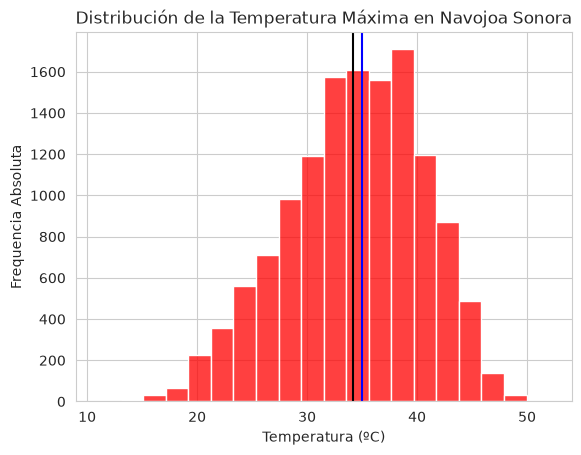

In [21]:
# Show the distribution of observed temperatures: taller bars indicate more observations in that range.
# Histogram of recorded daily maximum temperatures.
# Configure the plot for the histogram.
sns.set_style("whitegrid")

# Calculate the mean and median to compare their locations.
TMaxmed = df["Tmax (°C)"].median() 
TMaxprom = df["Tmax (°C)"].mean()

sns.histplot(data=df, x="Tmax (°C)", bins=20, color="r");
# Add reference lines marking the median and mean.
plt.axvline(x = TMaxmed, color = 'b', label = 'm') 
plt.axvline(x = TMaxprom, color = 'black', label = 'x')

# Label the plot axes.
plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Absoluta')
plt.title('Distribución de la Temperatura Máxima en Navojoa Sonora')

plt.show()


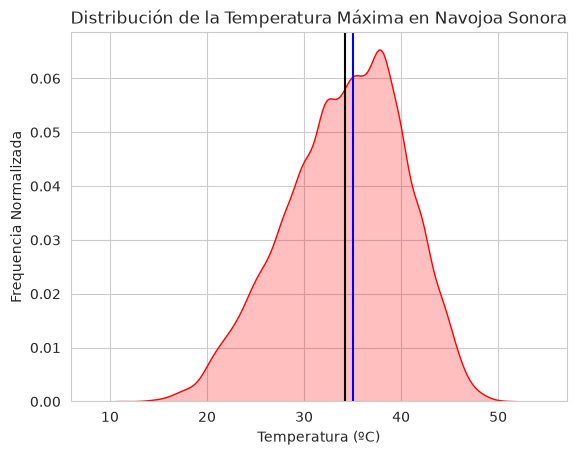

In [22]:
# Estimate a smooth curve that describes the distribution of observed temperatures (KDE).
# Kernel density estimate (KDE) plot.
# This smooth curve estimates the distribution of recorded values.
sns.set_style("whitegrid")

sns.kdeplot(df["Tmax (°C)"], fill=True, color="r");
plt.axvline(TMaxmed, color = 'b'); 
plt.axvline(TMaxprom, color = 'black');

plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Normalizada')
plt.title('Distribución de la Temperatura Máxima en Navojoa Sonora')

plt.show()

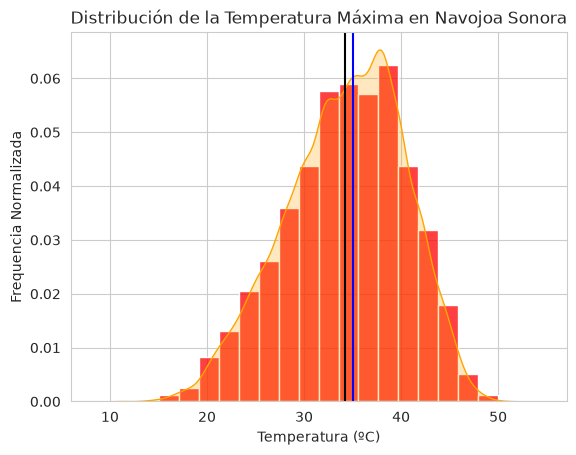

In [23]:
# Show the distribution of observed temperatures: taller bars indicate more observations in that range.
# Overlay the histogram and KDE on one figure.
# Configure the plotting style again.
sns.set_style("whitegrid")

sns.histplot(data=df, x="Tmax (°C)", bins=20, stat='density', color="r");
sns.kdeplot(df["Tmax (°C)"], fill=True, color="orange");

plt.axvline(TMaxmed, color = 'b'); 
plt.axvline(TMaxprom, color = 'black');

plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Normalizada')
plt.title('Distribución de la Temperatura Máxima en Navojoa Sonora')

plt.show()


## Temperature distributions

Histograms, kernel density estimates (KDE) and boxplots describe the range, shape, and unusual values of recorded temperatures. These are descriptive graphs, not trends over time.

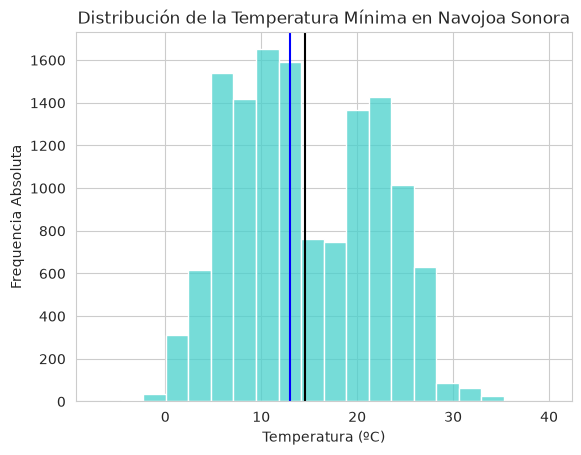

In [24]:
# Show the distribution of observed temperatures: taller bars indicate more observations in that range.
# Histogram of recorded daily minimum temperatures.
# Configure the plot for the histogram.
sns.set_style("whitegrid")

# Calculate the mean and median to compare their locations.
TMinmed = df["Tmin (°C)"].median() 
TMinprom = df["Tmin (°C)"].mean()

sns.histplot(data=df, x="Tmin (°C)", bins=20, color='#48D1CC');
# Add reference lines marking the median and mean.
plt.axvline(x = TMinmed, color = 'b', label = 'm') 
plt.axvline(x = TMinprom, color = 'black', label = 'x')

# Label the plot axes.
plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Absoluta')
plt.title('Distribución de la Temperatura Mínima en Navojoa Sonora')

plt.show()

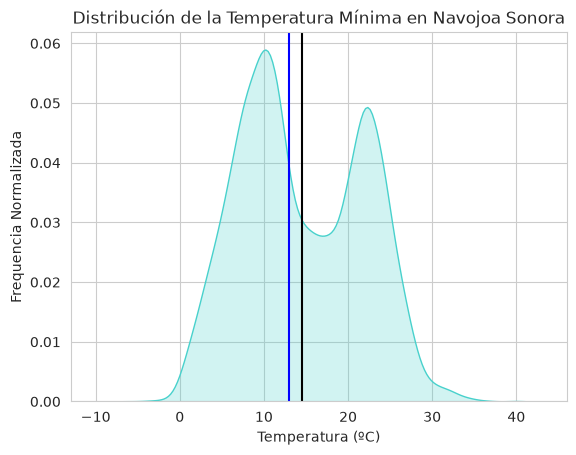

In [25]:
# Estimate a smooth curve that describes the distribution of observed temperatures (KDE).
# Kernel density estimate (KDE) plot.
# This smooth curve estimates the distribution of recorded values.
sns.set_style("whitegrid")

sns.kdeplot(df["Tmin (°C)"], fill=True, color='#48D1CC');
plt.axvline(TMinmed, color = 'b'); 
plt.axvline(TMinprom, color = 'black');

plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Normalizada')
plt.title('Distribución de la Temperatura Mínima en Navojoa Sonora')

plt.show()

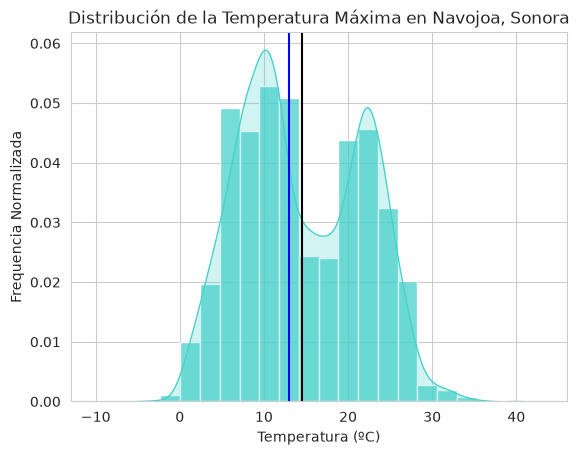

In [26]:
# Show the distribution of observed temperatures: taller bars indicate more observations in that range.
# Overlay the histogram and KDE on one figure.
# Configure the plotting style again.
sns.set_style("whitegrid")

sns.histplot(data=df, x="Tmin (°C)", bins=20, stat='density', color='#48D1CC');
sns.kdeplot(df["Tmin (°C)"], fill=True, color="#48D1CC");

plt.axvline(TMinmed, color = 'b'); 
plt.axvline(TMinprom, color = 'black');

plt.xlabel('Temperatura (ºC)')
plt.ylabel('Frequencia Normalizada')
plt.title('Distribución de la Temperatura Máxima en Navojoa, Sonora')

plt.show()

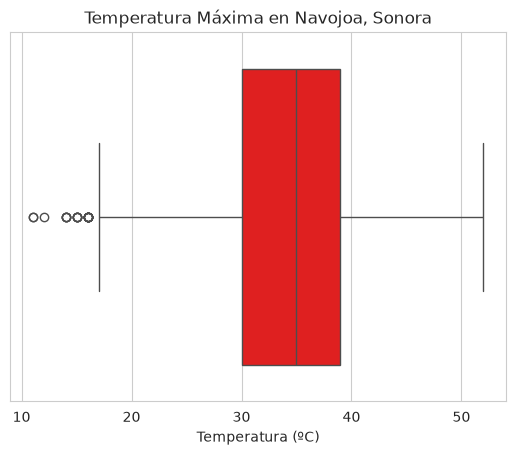

In [27]:
# Summarize median, spread and possible extreme observations with a boxplot.
# Boxplot of daily maximum temperatures.
# Configure the plotting style.
sns.set_style("whitegrid")
# Draw the boxplot to show the median, spread, and possible outliers.
sns.boxplot(x=df["Tmax (°C)"], data=df, orient='h',color="red").set(xlabel='Temperatura (ºC)', 
                                                     title='Temperatura Máxima en Navojoa, Sonora');

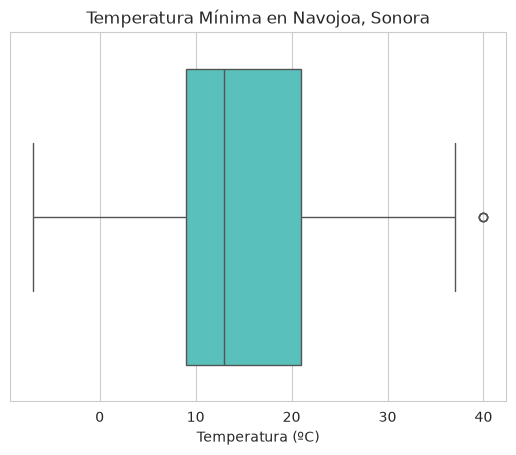

In [28]:
# Summarize median, spread and possible extreme observations with a boxplot.
# Boxplot of daily minimum temperatures.
# Configure the plotting style.
sns.set_style("whitegrid")
# Draw the boxplot to show the median, spread, and possible outliers.
sns.boxplot(x=df["Tmin (°C)"], data=df, orient='h',color='#48D1CC').set(xlabel='Temperatura (ºC)', 
                                                     title='Temperatura Mínima en Navojoa, Sonora');